In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
nd, ns, n, b, bk, beta = 200, 300, 10, 2., 5.5, 13.5153
f_exp = n/nd
gamma = 1 - f_exp/50
# delta_th = 2 * jnp.sqrt(f_exp*(1-f_exp)*(1-gamma)/(1+gamma))
delta_th = f_exp/2*1000
delta = 0.05
rng = jax.random.PRNGKey(333)
rng, rng1, rng2 = jax.random.split(rng, 3)

hyper = neurons.HyperConfig2(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta, gamma=gamma, delta_th=delta_th, delta=delta)
hyperD = neurons.HyperDynConfig2(b=b, bk=bk, beta=beta, gamma=gamma, delta_th=delta_th, delta=delta)
neuron = neurons.Neuron_Decay_Int2(hyper)
# xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)
xs_gen = input_gen.Normal_random_scaled(nd=hyper.nd, ns=hyper.ns, rng=rng1)

my_driver = driver.Driver2_shift_freq_record(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=rng2,
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000
)

# my_driver = driver.Driver1_bScan_activationScan(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     rng=rng2,
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000,
#     n_tested_patterns=1000,
# )

In [3]:
n_steps = 30000
my_driver.run(n_steps=n_steps)

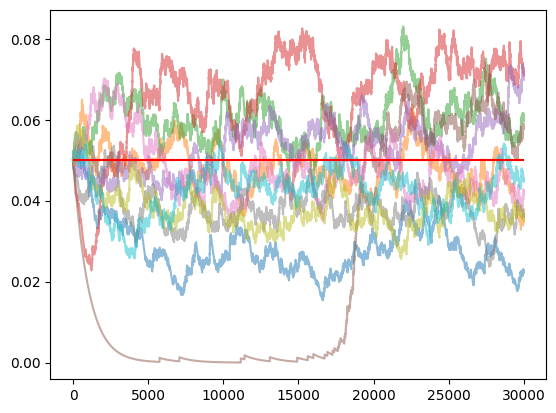

In [9]:
for i in range(10):
    plt.plot(my_driver.freq_record[:, i], alpha=0.5)
plt.hlines(f_exp, 0, n_steps, color='red')
# plt.hlines(f_exp+delta_th, 0, n_steps, color='red')
# plt.hlines(f_exp-delta_th, 0, n_steps, color='red')
# plt.xlim(25000, 26000)

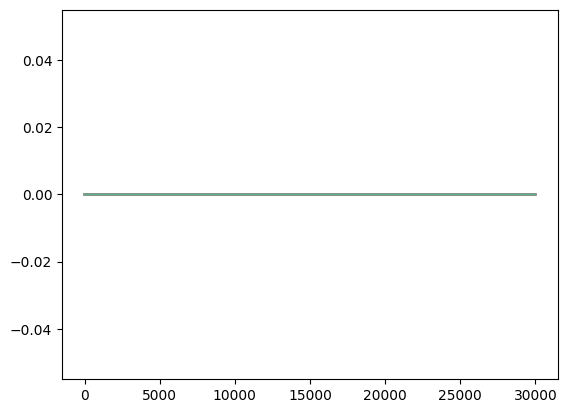

In [5]:
for i in range(10):
    plt.plot(my_driver.shift_record[:, i], alpha=0.5)
# plt.xlim(25000, 26000)

In [6]:
1/(1-gamma)

999.9999999999991

In [7]:
my_driver.freq_record

array([[0.04995   , 0.04995   , 0.04995   , ..., 0.04995   , 0.04995   ,
        0.05094999],
       [0.04990005, 0.04990005, 0.04990005, ..., 0.05090004, 0.04990005,
        0.05089904],
       [0.04985015, 0.04985015, 0.04985015, ..., 0.05084914, 0.04985015,
        0.05084814],
       ...,
       [0.02229783, 0.03699704, 0.05958385, ..., 0.03001451, 0.03467332,
        0.03611172],
       [0.02227553, 0.03796003, 0.06052426, ..., 0.02998449, 0.03463865,
        0.03607561],
       [0.02225325, 0.03792207, 0.06046373, ..., 0.02995451, 0.03460401,
        0.03603953]], shape=(30000, 200), dtype=float32)